# Early-baseline check

How would PRIME's online prediction performance look if the TEP had been computed with a different
baseline window?

This notebook replays the online TEP computation of one session trial by trial: same code
(`prime_core`), same stored calibration (`calibration_bundle.npy`, `dipole_fitting_info.npy`), same
trials. It changes exactly one thing, the baseline window used by the two `apply_baseline` calls
in `Preprocessor.preprocess_post`. Online that window is [−25, −15] ms; here it is `BASELINE`
(default [−105, −70] ms). The resulting raw dipole amplitude (µAm) is then compared with PRIME's
online predictions.

1. Load the trials and PRIME's predictions
2. Restore the online calibration state
3. Replay function
4. Check the replay against the online result
5. Replay all single-pulse trials with the new baseline, compare its rejections with the online ones, and pick the trial set (`REJECTION`)
6. Prediction vs. TEP amplitude (all single pulses, predetermined only, PRIME singles only)
7. TEP amplitude: `prime_single_pulse` vs. `predetermined_single` (with and without forced trials)
8. The same comparison with the online and the new baseline side by side

In [ ]:
# ---------------------------------------------------------------- parameters
SUBJECT_ID = "pilot003"     # BIDS subject label, without "sub-"
SESSION_ID = "ses-prime"
RUN_ID     = "103"          # NeuroSimo run folder

BASELINE = (-0.165, -0.066)   # s, new baseline window (online: -0.025, -0.015)

REJECTION = "online"          # which trials are analysed:
                              #   "online" = the trials the online pipeline kept (postprocessing_failed == False)
                              #   "new"    = the trials the online reject gates keep when replayed with BASELINE

## Setup

Imports and paths. `prime/decider` is put on `sys.path`, so `Preprocessor` and `DipoleFitter` are
the same classes `2_intervention.py` runs online. `FORWARD_PATH` is the forward solution the decider
loads.

In [158]:
import os, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})
COLOR_PREDETERMINED = "#5b8ff9"   # same colours as PRIME_online_performance.ipynb
COLOR_PRIME_SINGLE  = "#e8684a"


def _find_loop_root() -> Path:
    env = os.environ.get("LOOP_ROOT")
    candidates = [env] if env else []
    candidates += [r"D:\Linus\Loop", str(Path.home() / "Desktop" / "Loop")]
    for c in candidates:
        if c and (Path(c) / "BIDS").is_dir() and (Path(c) / "prime").is_dir():
            return Path(c)
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "BIDS").is_dir() and (d / "prime").is_dir():
            return d
    raise FileNotFoundError("Loop root not found; set the LOOP_ROOT environment variable.")


LOOP_ROOT    = _find_loop_root()
SUBJECT_DIR  = LOOP_ROOT / "BIDS" / f"sub-{SUBJECT_ID}" / SESSION_ID / RUN_ID / "prime"
DECIDER_DIR  = LOOP_ROOT / "prime" / "decider"
FORWARD_PATH = LOOP_ROOT / "prime" / "offline_data" / "fsaverage" / "fsaverage-fwd.fif"
OUTPUT_DIR   = LOOP_ROOT / "scripts_analysis" / "early_baseline_check_outputs"
for p in (SUBJECT_DIR, DECIDER_DIR, FORWARD_PATH):
    if not p.exists():
        raise FileNotFoundError(p)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sys.dont_write_bytecode = True             # read-only use of prime/: no __pycache__ files written there
sys.path.insert(0, str(DECIDER_DIR))
from prime_core.preprocessing.preprocessor import Preprocessor
from prime_core.preprocessing.dipole_fitter import DipoleFitter
from prime_core.preprocessing.config import get_default_config
from prime_core.prime_config import (
    get_raw_sfreq, get_processed_sfreq, get_qc_time_range,
    get_post_initial_time_range, get_post_time_range, get_dipole_time_range,
)

RAW_SFREQ, PROC_SFREQ    = get_raw_sfreq(), get_processed_sfreq()   # 5000 / 1000 Hz
QC_TMIN, QC_TMAX         = get_qc_time_range()             # _pre_raw.npy  window [-210, -10] ms
POST_I_TMIN, POST_I_TMAX = get_post_initial_time_range()   # _post_raw.npy window [-30, 100] ms
POST_TMIN, POST_TMAX     = get_post_time_range()           # processed post epoch [1, 100] ms
DIP_TMIN, DIP_TMAX       = get_dipole_time_range()         # dipole window [38, 50] ms
ONLINE_BASELINE          = tuple(get_default_config().baseline)   # [-25, -15] ms

ms = lambda w: f"[{w[0] * 1e3:.0f}, {w[1] * 1e3:.0f}] ms"
print(f"session         : {SUBJECT_DIR.relative_to(LOOP_ROOT)}")
print(f"online baseline : {ms(ONLINE_BASELINE)}")
print(f"new baseline    : {ms(BASELINE)}")
if REJECTION not in ("online", "new"):
    raise ValueError('REJECTION must be "online" or "new"')
print(f"rejections      : {REJECTION}")

session         : BIDS\sub-pilot004\ses-prime\104\prime
online baseline : [-25, -15] ms
new baseline    : [-165, -66] ms
rejections      : online


## 1 · Trials and PRIME predictions

`trials_intervention.csv` has one row per calibration and intervention trial. Columns used here:

- **`condition`**: only single-pulse trials are replayed (`predetermined_single`,
  `prime_single_pulse`). `prime_triplet` is left out because its 2nd and 3rd pulses land before or
  inside the dipole window, and online it never received a normalised label.
- **`postprocessing_failed`** / **`post_reject_reason`**: trials the online pipeline rejected
  (ocular, global MAD, local MAD). With `REJECTION = "online"` these trials are left out. With
  `"new"`, the rejections of the online gates replayed with `BASELINE` decide instead (section 5).
- **`tep_amplitude_raw`**: the online raw dipole amplitude (µAm, online baseline). This is the
  reference. It is empty for trials rejected online.
- **`prediction_probability`**: PRIME's prediction. For `prime_single_pulse` it is the probability
  that crossed the threshold and triggered the pulse, which is the triggering row of
  `prime_predictions.csv` (checked below). Forced trials have none. For `predetermined_single` it
  is the retrospective prediction on the pre-stimulus window, made online after the pulse, and only
  if the trial passed postprocessing.
- **`is_forced`**: the trial hit `PRIME_MAX_WAIT` and was triggered without a prediction.

In [159]:
trials = pd.read_csv(SUBJECT_DIR / "trials_intervention.csv")
IV = trials[trials.stage.str.startswith("intervention_block")].copy()
IV = IV.sort_values(["stage", "trial_in_stage"]).reset_index(drop=True)
IV["trial_order"] = np.arange(len(IV))                     # position in the session (trend plots)
IV["is_forced"] = IV.is_forced.astype(bool)
IV["postprocessing_failed"] = IV.postprocessing_failed.astype(bool)
IV["stem"] = IV.stage + "_" + IV.trial_in_stage.map("{:04d}".format)
BLOCK_EDGES = IV.groupby("stage", sort=False).size().cumsum().values[:-1]

SINGLES = ["predetermined_single", "prime_single_pulse"]
singles = IV[IV.condition.isin(SINGLES)].copy()             # all single pulses, kept and rejected online

display(pd.crosstab(IV.condition, IV.postprocessing_failed.map({False: "kept", True: "rejected online"})))
n_forced = int(((singles.condition == "prime_single_pulse") & singles.is_forced).sum())
print(f"{len(singles)} single-pulse trials, {int((~singles.postprocessing_failed).sum())} kept online "
      f"({n_forced} forced prime_single_pulse)")

# PRIME's prediction log: the triggering attempt must carry the per-trial prediction_probability
pred_path = SUBJECT_DIR / "prime_predictions.csv"
if pred_path.is_file():
    preds = pd.read_csv(pred_path)
    trig = preds[preds.triggered.astype(bool) & ~preds.forced.astype(bool)]
    chk = singles.merge(trig[["stage", "trial_in_stage", "probability"]], on=["stage", "trial_in_stage"])
    print(f"prime_predictions.csv: {len(preds)} attempts; triggering attempt vs. prediction_probability: "
          f"max |diff| = {np.abs(chk.probability - chk.prediction_probability).max():.1g} ({len(chk)} trials)")

postprocessing_failed,kept,rejected online
condition,,
predetermined_single,73,7
prime_single_pulse,217,23
prime_triplet,422,58


320 single-pulse trials, 290 kept online (21 forced prime_single_pulse)
prime_predictions.csv: 48000 attempts; triggering attempt vs. prediction_probability: max |diff| = 5e-10 (219 trials)


## 2 · Restore the online calibration state

At the end of `run_calibration()` the decider saved `calibration_bundle.npy` (bad channels and
their interpolation matrix, ICA, SOUND filter, SSP-SIR matrices, reject statistics; spelled
`calibration_bunble.npy` in older sessions) and `dipole_fitting_info.npy` (source position,
orientation, and index range within the dipole window). `Preprocessor.from_bundle` restores the
preprocessor (step 3). `DipoleFitter` has no restore method, so the stored fitting info is assigned
directly, which is exactly what `calibrate()` sets.

**Units.** The online EEG stream is in µV and the leadfield in V/(A·m), so `fit_trial` returns the
dipole moment in µAm (0.05 µAm = 50 nAm). `tep_amplitude_raw` is in the same unit, so no
conversion is needed.

In [160]:
bundle_path = [p for p in (SUBJECT_DIR / "calibration_bundle.npy", SUBJECT_DIR / "calibration_bunble.npy") if p.is_file()]
if not bundle_path:
    raise FileNotFoundError(f"no calibration bundle in {SUBJECT_DIR}")
if not (SUBJECT_DIR / "dipole_fitting_info.npy").is_file():
    raise FileNotFoundError("no dipole_fitting_info.npy for this session (see replay_dipole_fit.ipynb)")

bundle = np.load(bundle_path[0], allow_pickle=True).item()
fitting_info = np.load(SUBJECT_DIR / "dipole_fitting_info.npy", allow_pickle=True).item()

fitter = DipoleFitter(FORWARD_PATH)
fitter._fitting_info = fitting_info

print(f"calibration bundle : {bundle_path[0].name}")
print(f"bad channels       : {', '.join(bundle['bad_channels']) or 'none'} (interpolated)")
print(f"dipole             : vertex {fitting_info['position_index']}, index_range {fitting_info['index_range']} "
      f"within {ms((DIP_TMIN, DIP_TMAX))}, free orientation (as online)")

calibration bundle : calibration_bundle.npy
bad channels       : Fz, P4, P8 (interpolated)
dipole             : vertex 7558, index_range (6, 12) within [38, 50] ms, free orientation (as online)


## 3 · The replay

Online, `analyze_tep` passes the raw [−30, 100] ms buffer to `Preprocessor.preprocess_post`:

resample 5 → 1 kHz → **baseline #1** → artifact interpolation [−14, 14] ms → bad-channel
interpolation → average reference → ICA (ocular components removed) → **baseline #2** → average
reference → crop to [1, 100] ms → SOUND → average reference → SSP-SIR → artifact interpolation
[1, 15] ms → average reference → dipole window [38, 50] ms.

Then `DipoleFitter.fit_trial` fits a free-orientation dipole at the stored position, over the stored
`index_range`.

The replay calls the same `preprocess_post` and `fit_trial` with the stored parameters and changes
two attributes of the preprocessor, nothing else:

1. `_cfg.baseline = BASELINE`, the window both `apply_baseline` calls use.
2. `_post_initial_tmin = −210 ms`. The saved `_post_raw.npy` starts at −30 ms, so it cannot contain
   the new window. `_pre_raw.npy` ([−210, −10] ms) was cut from the same pulse-aligned buffer.
   The two overlap sample for sample over [−30, −10] ms (asserted for every trial), so they are
   joined into one [−210, 100] ms raw buffer. The polyphase resample only uses about 10 ms on either
   side of a sample, so the post-stimulus samples come out the same as online. Step 4 confirms that
   the longer buffer changes nothing on its own.

**Rejection.** `preprocess_post` also runs the online reject gates (ocular, global MAD, local MAD)
with their stored thresholds. The ocular gate picks its samples by index, so those indices are
shifted by the 180 extra samples of the longer buffer, and the gate still looks at [15, 100] ms.
With `BASELINE`, the gates' verdict is the *new* rejection. `REJECTION` at the top chooses whether
it or the online rejection defines the analysed trials (section 5). The gate statistics were
calibrated with the online baseline, so the new rejection leans towards too many ocular rejections.
The epoch for the dipole fit is read from `last_post_full`, which is captured just before the gates
(the buffer the decider saves as `_post_proc.npy`), so every trial gets an amplitude, rejected or
not.

In [161]:
N_OVERLAP = int(round((POST_I_TMIN - QC_TMIN) * RAW_SFREQ))           # _pre_raw samples before -30 ms (900)
i0 = int(round((DIP_TMIN - POST_TMIN) * PROC_SFREQ))
DIP_IDX = slice(i0, i0 + int(round((DIP_TMAX - DIP_TMIN) * PROC_SFREQ)) + 1)   # [38, 50] ms in the [1, 100] ms epoch


def make_preprocessor(baseline, post_initial_tmin):
    # The online Preprocessor restored from the bundle; only the baseline and the raw buffer start differ.
    # The ocular gate's sample indices are shifted with the buffer start so it still looks at [15, 100] ms.
    shift = int(round((POST_I_TMIN - post_initial_tmin) * PROC_SFREQ))   # 0 online, 180 for the stitched buffer
    params = dict(bundle)
    params["ocular_threshold_post"] = {
        comp: {**info, "time_indices_of_interest": info["time_indices_of_interest"] + shift}
        for comp, info in bundle["ocular_threshold_post"].items()}
    pp = Preprocessor.from_bundle(params, FORWARD_PATH)
    pp.keep_full_epochs = True                 # as online (fills last_post_full)
    pp._cfg.baseline = list(baseline)
    pp._post_initial_tmin = post_initial_tmin
    return pp


def load_raw(stem):
    # Saved raw buffers of one trial -> (post_raw [-30, 100] ms, stitched [-210, 100] ms), (n_samples, 60) at 5 kHz.
    pre = np.load(SUBJECT_DIR / f"{stem}_pre_raw.npy")
    post = np.load(SUBJECT_DIR / f"{stem}_post_raw.npy")
    if not np.array_equal(pre[N_OVERLAP:], post[:len(pre) - N_OVERLAP]):
        raise ValueError(f"{stem}: _pre_raw and _post_raw do not overlap")
    return post, np.vstack([pre[:N_OVERLAP], post])


def replay_trial(pp, raw, tmin):
    # preprocess_post + fit_trial as in analyze_tep(), on a raw buffer starting at tmin.
    # Returns (dipole amplitude in µAm, reject reason of the online gates or None).
    times = tmin + np.arange(raw.shape[0]) / RAW_SFREQ
    pp.preprocess_post(raw, times)
    return fitter.fit_trial(pp.last_post_full[:, DIP_IDX]), pp.last_post_reject_reason


if not (QC_TMIN <= BASELINE[0] < BASELINE[1] <= 0):
    raise ValueError(f"BASELINE must lie within the stitched buffer, {ms((QC_TMIN, 0))}")
pp_new = make_preprocessor(BASELINE, QC_TMIN)
print(f"replay buffer {ms((QC_TMIN, POST_I_TMAX))}, baseline {ms(BASELINE)}, "
      f"dipole samples {DIP_IDX.start}-{DIP_IDX.stop - 1} of the [1, 100] ms epoch")

replay buffer [-210, 100] ms, baseline [-165, -66] ms, dipole samples 37-49 of the [1, 100] ms epoch


## 4 · Check: does the replay reproduce the online result?

Two checks on the first `N_CHECK` trials, both with the online baseline:

- **(a)** the saved [−30, 100] ms buffer, exactly as online. This must equal `tep_amplitude_raw`.
- **(b)** the stitched [−210, 100] ms buffer. This shows that the longer buffer alone changes almost
  nothing. The small remaining difference is the resample edge that the online buffer had at −30 ms,
  next to the online baseline window.

In [162]:
N_CHECK = 25

pp_online        = make_preprocessor(ONLINE_BASELINE, POST_I_TMIN)   # exactly the online object
pp_online_long   = make_preprocessor(ONLINE_BASELINE, QC_TMIN)

rows = []
for r in singles[~singles.postprocessing_failed].head(N_CHECK).itertuples():
    post, stitched = load_raw(r.stem)
    rows.append((r.tep_amplitude_raw,
                 replay_trial(pp_online, post, POST_I_TMIN)[0],
                 replay_trial(pp_online_long, stitched, QC_TMIN)[0]))
check = pd.DataFrame(rows, columns=["online", "a_replay", "b_stitched"])

print(f"(a) online buffer   : max |replay - tep_amplitude_raw| = {np.abs(check.a_replay - check.online).max():.1e} µAm")
print(f"(b) stitched buffer : max relative difference to tep_amplitude_raw = {np.abs(check.b_stitched / check.online - 1).max():.3%}")

(a) online buffer   : max |replay - tep_amplitude_raw| = 4.8e-10 µAm
(b) stitched buffer : max relative difference to tep_amplitude_raw = 0.016%


## 5 · Replay with the new baseline, and choose the rejections

Every single-pulse trial is replayed with `BASELINE`, including those rejected online, so both
rejections are known for every trial. `amp_new` is the replay with `BASELINE`, and `amp_online` is
`tep_amplitude_raw` (online baseline). Trials rejected online have no `tep_amplitude_raw`, so for
them `amp_online` is replayed from the saved buffer exactly as online (section 4a). Both are in µAm.

The difference between the two rejections is printed either way. `REJECTION` then picks the
analysed trial set (`kept`) for sections 6–7. The per-trial table with both rejections is written to
`scripts_analysis/early_baseline_check_outputs/`.

In [163]:
t0 = time.time()
rows = []
for r in singles.itertuples():
    post, stitched = load_raw(r.stem)
    amp, why = replay_trial(pp_new, stitched, QC_TMIN)
    amp_on = replay_trial(pp_online, post, POST_I_TMIN)[0] if r.postprocessing_failed else r.tep_amplitude_raw
    rows.append((amp_on, amp, why))
singles["amp_online"] = [a for a, _, _ in rows]
singles["amp_new"] = [a for _, a, _ in rows]
singles["rejected_online"] = singles.postprocessing_failed
singles["reject_reason_online"] = singles.post_reject_reason
singles["reject_reason_new"] = [w for _, _, w in rows]
singles["rejected_new"] = singles.reject_reason_new.notna()
print(f"{len(singles)} trials replayed in {time.time() - t0:.0f} s\n")

# ---------------------------------------------------------------- difference between the two rejections
display(pd.crosstab(singles.rejected_online.map({False: "kept online", True: "rejected online"}),
                    singles.rejected_new.map({False: "kept, new baseline", True: "rejected, new baseline"})))
only_online = singles[singles.rejected_online & ~singles.rejected_new]
only_new = singles[~singles.rejected_online & singles.rejected_new]
print(f"rejected online only, kept with the new baseline ({len(only_online)}):")
for r in only_online.itertuples():
    print(f"  {r.stem}  {r.condition:<20}  online: {r.reject_reason_online}")
print(f"\nrejected with the new baseline only, kept online ({len(only_new)}):")
for r in only_new.itertuples():
    print(f"  {r.stem}  {r.condition:<20}  new: {r.reject_reason_new}")

# ---------------------------------------------------------------- analysed trial set
kept = singles[~singles.rejected_online if REJECTION == "online" else ~singles.rejected_new].copy()
print(f"\nREJECTION = {REJECTION!r}: {len(kept)} of {len(singles)} single-pulse trials analysed in sections 6-7\n")

display(kept.groupby("condition")[["amp_online", "amp_new"]].agg(["count", "median", "mean", "std"]).round(4))
r_on_new = stats.pearsonr(kept.amp_online, kept.amp_new)[0]
print(f"trial-wise agreement, online vs. new baseline: Pearson r = {r_on_new:.3f}")

out_csv = OUTPUT_DIR / f"{SUBJECT_ID}_baseline_{BASELINE[0] * 1e3:.0f}_{BASELINE[1] * 1e3:.0f}ms.csv"
singles[["stage", "trial_in_stage", "condition", "is_forced", "trial_order", "prediction_probability",
         "amp_online", "amp_new", "rejected_online", "reject_reason_online",
         "rejected_new", "reject_reason_new"]].to_csv(out_csv, index=False)
print(f"saved: {out_csv.relative_to(LOOP_ROOT)}")

320 trials replayed in 15 s



rejected_new,"kept, new baseline","rejected, new baseline"
rejected_online,,
kept online,264,26
rejected online,11,19


rejected online only, kept with the new baseline (11):
  intervention_block_1_0054  prime_single_pulse    online: ocular
  intervention_block_1_0103  prime_single_pulse    online: global_mad
  intervention_block_1_0126  predetermined_single  online: ocular
  intervention_block_1_0133  prime_single_pulse    online: ocular
  intervention_block_2_0017  prime_single_pulse    online: ocular
  intervention_block_2_0183  prime_single_pulse    online: ocular
  intervention_block_3_0004  predetermined_single  online: ocular
  intervention_block_3_0114  prime_single_pulse    online: ocular
  intervention_block_4_0005  prime_single_pulse    online: ocular
  intervention_block_4_0101  predetermined_single  online: ocular
  intervention_block_4_0162  prime_single_pulse    online: ocular

rejected with the new baseline only, kept online (26):
  intervention_block_1_0038  prime_single_pulse    new: ocular
  intervention_block_1_0042  predetermined_single  new: ocular
  intervention_block_1_0048  prim

amp_online                         amp_new          \
                          count  median    mean     std   count  median   
condition                                                                 
predetermined_single         73  0.1019  0.1128  0.0528      73  0.0888   
prime_single_pulse          217  0.1247  0.1387  0.0690     217  0.0977   

                                      
                        mean     std  
condition                             
predetermined_single  0.0982  0.0459  
prime_single_pulse    0.1069  0.0473

trial-wise agreement, online vs. new baseline: Pearson r = 0.608
saved: scripts_analysis\early_baseline_check_outputs\pilot004_baseline_-165_-66ms.csv


## 6 · PRIME prediction vs. TEP amplitude

Each figure shows the same trials twice: on the left with the online baseline (`amp_online`), on
the right with the new baseline. Only trials with a prediction are included. This drops forced
`prime_single_pulse` trials (no prediction) and `predetermined_single` trials that online never
predicted: those whose pre-stimulus window failed preprocessing and, with `REJECTION = "new"`,
those rejected online. The line is a least-squares fit over all
plotted trials.

A caveat when reading these: `prime_single_pulse` trials only exist where the prediction crossed
the threshold (range restriction). `predetermined_single` trials fire on a clock and are the
unselected comparison.

In [164]:
CORR = {}   # collected for the summary


def corr_plot(d, name):
    d = d.dropna(subset=["prediction_probability"])
    if len(d) < 3:
        print(f"{name}: fewer than 3 trials with a prediction, skipped")
        return
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
    for ax, col, label in [(axes[0], "amp_online", f"online baseline {ms(ONLINE_BASELINE)}"),
                           (axes[1], "amp_new",    f"new baseline {ms(BASELINE)}")]:
        for cond, color in [("predetermined_single", COLOR_PREDETERMINED), ("prime_single_pulse", COLOR_PRIME_SINGLE)]:
            dc = d[d.condition == cond]
            if len(dc):
                ax.scatter(dc.prediction_probability, dc[col], s=14, alpha=0.55, color=color, label=f"{cond} (n={len(dc)})")
        b1, b0 = np.polyfit(d.prediction_probability, d[col], 1)
        xs = np.linspace(d.prediction_probability.min(), d.prediction_probability.max(), 20)
        ax.plot(xs, b0 + b1 * xs, color="0.25", lw=1.5)
        r, p = stats.pearsonr(d.prediction_probability, d[col])
        rho, p_s = stats.spearmanr(d.prediction_probability, d[col])
        CORR[(name, col)] = (len(d), r, p, rho, p_s)
        ax.set_title(f"{label}\nPearson r = {r:+.3f} (p = {p:.3g})   Spearman ρ = {rho:+.3f} (p = {p_s:.3g})", fontsize=10)
        ax.set_xlabel("prediction_probability")
        ax.legend(fontsize=8, loc="upper left")
    axes[0].set_ylabel("dipole amplitude (µAm)")
    fig.suptitle(f"{name}: prediction vs. TEP amplitude (n = {len(d)})", y=1.02)
    fig.tight_layout()
    plt.show()

### 6a · All single-pulse trials

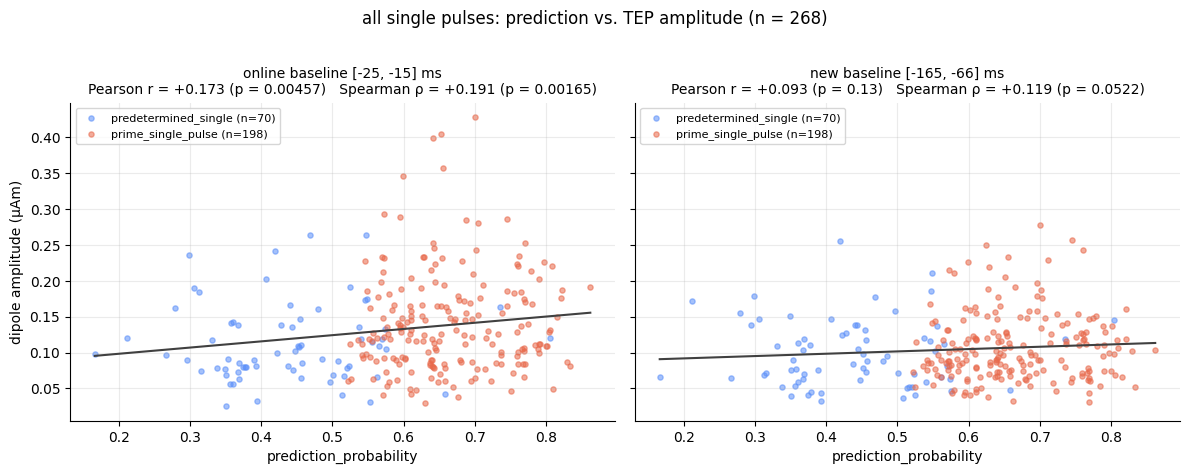

In [165]:
corr_plot(kept, "all single pulses")

### 6b · `predetermined_single` only

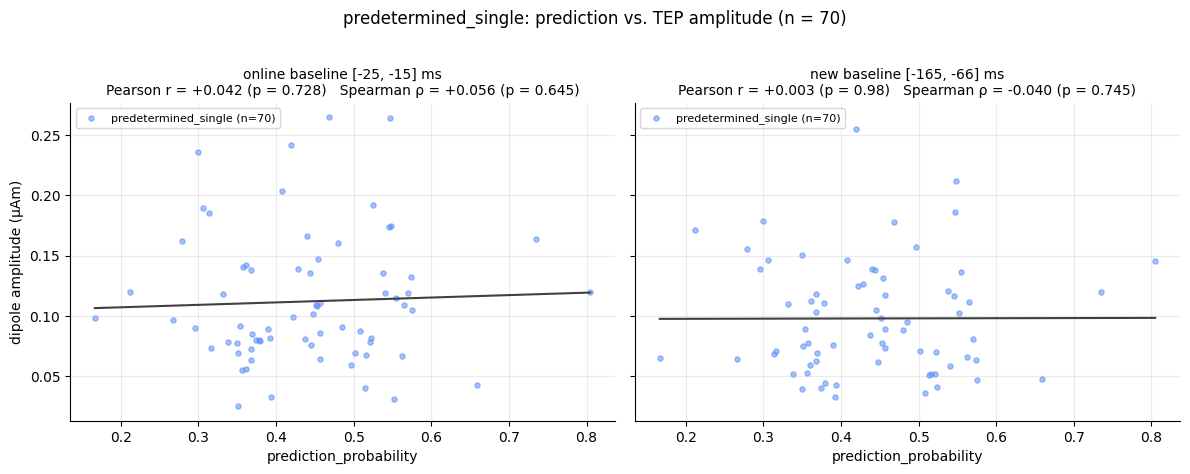

In [166]:
corr_plot(kept[kept.condition == "predetermined_single"], "predetermined_single")

### 6c · `prime_single_pulse` only, forced trials excluded

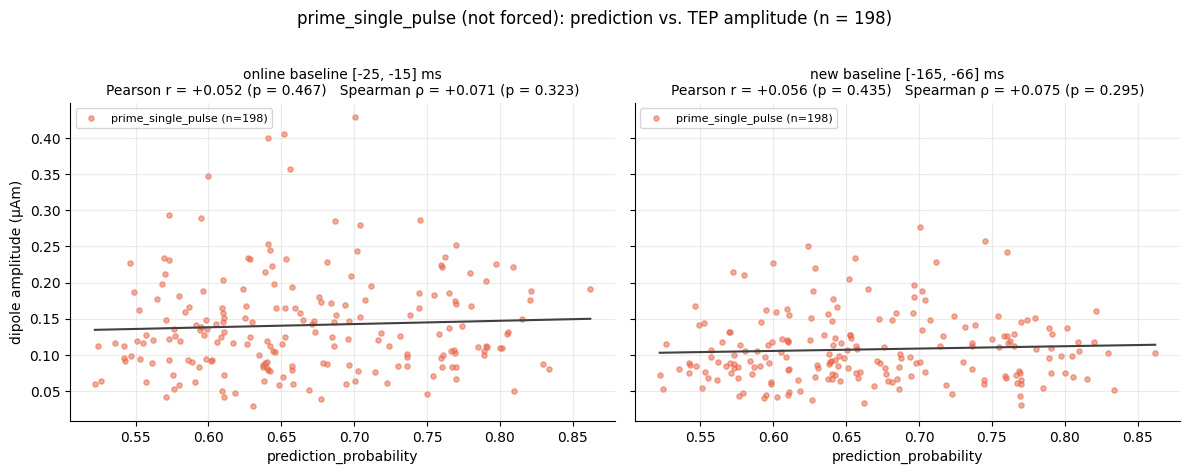

In [167]:
corr_plot(kept[(kept.condition == "prime_single_pulse") & ~kept.is_forced], "prime_single_pulse (not forced)")

## 7 · TEP amplitude: `prime_single_pulse` vs. `predetermined_single`

The same three views as section 8.8 of `PRIME_online_performance.ipynb`: the distribution, a
side-by-side box plot, and the trend across the session with a rolling mean. The difference is the
measure: here it is the raw dipole amplitude in µAm with the new baseline, not the normalised
`tep_amplitude`. Medians are printed below each figure. Dotted lines mark intervention-block
boundaries.

**Per-block effect sizes.** Below each figure, the prime − predetermined contrast is computed
separately for each intervention block and for all blocks pooled, as three measures:

- the difference in medians (µAm);
- the ratio of medians (prime / predetermined, so 1.10 means 10% larger);
- Cliff's δ, the probability that a random prime trial is larger than a random predetermined trial
  minus the reverse (−1 to 1, 0 = no difference). It uses ranks only, so it is robust to the skewed
  amplitude distribution.

The 95% CIs are percentile bootstrap intervals (5000 resamples, trials resampled with replacement
within each condition and block). The p-value is a two-sided Mann-Whitney U test. There are only
about 18 `predetermined_single` trials per block, so per-block CIs are wide. The pooled row is the
one to test on; the blocks show whether the contrast is stable across the session. The forest plot
shows the same numbers, with the pooled estimate to the right of the grey line.

In [168]:
MEDIANS = {}   # collected for the summary


def trend_plot(ax, df, ycol, conditions, colors, window=20):
    # Per-trial scatter over trial_order with a centred rolling mean per condition (as in PRIME_online_performance).
    for cond, color in zip(conditions, colors):
        d = df.loc[df.condition == cond, ["trial_order", ycol]].dropna().sort_values("trial_order")
        if d.empty:
            continue
        roll = d[ycol].rolling(window, min_periods=max(3, window // 3), center=True).mean()
        ax.scatter(d.trial_order, d[ycol], s=7, alpha=0.25, color=color)
        ax.plot(d.trial_order, roll, color=color, lw=1.8, label=f"{cond} (rolling mean, w={window})")
    for edge in BLOCK_EDGES:
        ax.axvline(edge, color="grey", lw=0.7, ls=":")
    ax.set_xlabel("trial order")
    ax.set_ylabel("dipole amplitude (µAm)")
    ax.legend(fontsize=8)


def amplitude_comparison(d, name, col="amp_new"):
    conds = [("predetermined_single", COLOR_PREDETERMINED), ("prime_single_pulse", COLOR_PRIME_SINGLE)]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))

    bins = np.linspace(0, d[col].max() * 1.02, 26)
    for cond, color in conds:
        axes[0].hist(d.loc[d.condition == cond, col], bins=bins, alpha=0.55, color=color, label=cond, density=True)
    axes[0].set_xlabel("dipole amplitude (µAm)")
    axes[0].set_ylabel("density")
    axes[0].set_title("Distribution")
    axes[0].legend(fontsize=8)

    bp = axes[1].boxplot([d.loc[d.condition == c, col] for c, _ in conds],
                         tick_labels=["predetermined_\nsingle", "prime_\nsingle_pulse"], patch_artist=True)
    for patch, (_, color) in zip(bp["boxes"], conds):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    axes[1].set_ylabel("dipole amplitude (µAm)")
    axes[1].set_title("Side by side")

    trend_plot(axes[2], d, col, [c for c, _ in conds], [c for _, c in conds])
    axes[2].set_title("Trend across the session")
    fig.suptitle(f"TEP amplitude, baseline {ms(BASELINE)}: {name} vs. predetermined_single", y=1.04)
    fig.tight_layout()
    plt.show()

    a = d.loc[d.condition == "prime_single_pulse", col]
    b = d.loc[d.condition == "predetermined_single", col]
    for c in ("amp_online", "amp_new"):
        MEDIANS[(name, c)] = (d.loc[d.condition == "prime_single_pulse", c].median(),
                              d.loc[d.condition == "predetermined_single", c].median(), len(a), len(b))
    print(f"prime_single_pulse   median = {a.median():.4f} µAm  (n={len(a)})")
    print(f"predetermined_single median = {b.median():.4f} µAm  (n={len(b)})")
    print(f"difference in medians (prime - predetermined) = {a.median() - b.median():+.4f} µAm")
    block_effect_report(d, name, [col])

# ---------------------------------------------------------------- per-block effect sizes (sections 7 and 8)
BLOCKS = list(dict.fromkeys(IV.stage))     # intervention blocks in session order
N_BOOT = 5000
EFFECTS = [("diff", "median difference, prime − predetermined (µAm)", 0.0),
           ("ratio", "median ratio, prime / predetermined", 1.0),
           ("delta", "Cliff's δ (> 0: prime larger)", 0.0)]
BASELINE_STYLE = {"amp_online": ("0.6", f"online baseline {ms(ONLINE_BASELINE)}"),
                  "amp_new": ("0.1", f"new baseline {ms(BASELINE)}")}


def _effects(a, b):
    # Median difference, median ratio and Cliff's delta of a (prime) vs. b (predetermined), along the last axis.
    ma, mb = np.median(a, axis=-1), np.median(b, axis=-1)
    ranks = stats.rankdata(np.concatenate([a, b], axis=-1), axis=-1)
    u = ranks[..., :a.shape[-1]].sum(axis=-1) - a.shape[-1] * (a.shape[-1] + 1) / 2   # Mann-Whitney U of a
    return ma - mb, ma / mb, 2 * u / (a.shape[-1] * b.shape[-1]) - 1


def block_effects(d, col, seed=0):
    # One row per intervention block plus all blocks pooled: estimates, bootstrap 95% CIs, Mann-Whitney p.
    rng = np.random.default_rng(seed)
    rows = []
    for block in BLOCKS + ["all blocks"]:
        db = d if block == "all blocks" else d[d.stage == block]
        a = db.loc[db.condition == "prime_single_pulse", col].dropna().to_numpy()
        b = db.loc[db.condition == "predetermined_single", col].dropna().to_numpy()
        if len(a) < 3 or len(b) < 3:
            continue
        est = _effects(a, b)
        boot = _effects(a[rng.integers(0, len(a), (N_BOOT, len(a)))], b[rng.integers(0, len(b), (N_BOOT, len(b)))])
        row = {"block": block.replace("intervention_block_", "block "), "n prime": len(a), "n predetermined": len(b)}
        for (key, _, _), e, bt in zip(EFFECTS, est, boot):
            row[key], (row[key + " lo"], row[key + " hi"]) = e, np.percentile(bt, [2.5, 97.5])
        row["p (MWU)"] = stats.mannwhitneyu(a, b).pvalue
        rows.append(row)
    return pd.DataFrame(rows).set_index("block")


def block_effect_report(d, name, cols):
    # Forest plot (one panel per measure, one colour per baseline) and a table of estimate [95% CI].
    tables = {c: block_effects(d, c) for c in cols}
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
    for k, (c, t) in enumerate(tables.items()):
        color, label = BASELINE_STYLE[c]
        x = np.arange(len(t)) + (k - (len(tables) - 1) / 2) * 0.2
        for ax, (key, _, _) in zip(axes, EFFECTS):
            ax.errorbar(x, t[key], yerr=[t[key] - t[key + " lo"], t[key + " hi"] - t[key]],
                        fmt="o", ms=5, capsize=3, color=color, label=label)
    for ax, (_, title, ref) in zip(axes, EFFECTS):
        ax.axhline(ref, color="0.4", lw=0.8, ls="--")
        ax.axvline(len(t) - 1.5, color="0.8", lw=1)
        ax.set_xticks(np.arange(len(t)))
        ax.set_xticklabels(t.index, fontsize=8)
        ax.set_title(title, fontsize=10)
    axes[0].set_ylabel("estimate, 95% bootstrap CI")
    axes[0].legend(fontsize=8)
    fig.suptitle(f"Per-block effect sizes: {name} vs. predetermined_single", y=1.04)
    fig.tight_layout()
    plt.show()

    def fmt(t):
        ci = lambda key, f: t.apply(lambda r: f"{r[key]:{f}} [{r[key + ' lo']:{f}}, {r[key + ' hi']:{f}}]", axis=1)
        return pd.DataFrame({"n prime": t["n prime"], "n predetermined": t["n predetermined"],
                             "median diff (µAm) [95% CI]": ci("diff", "+.4f"),
                             "ratio [95% CI]": ci("ratio", ".2f"),
                             "Cliff's δ [95% CI]": ci("delta", "+.2f"),
                             "p (MWU)": t["p (MWU)"].map("{:.3g}".format)})
    display(pd.concat({BASELINE_STYLE[c][1]: fmt(t) for c, t in tables.items()}, names=["baseline"]))

### 7a · All `prime_single_pulse` trials (forced included)

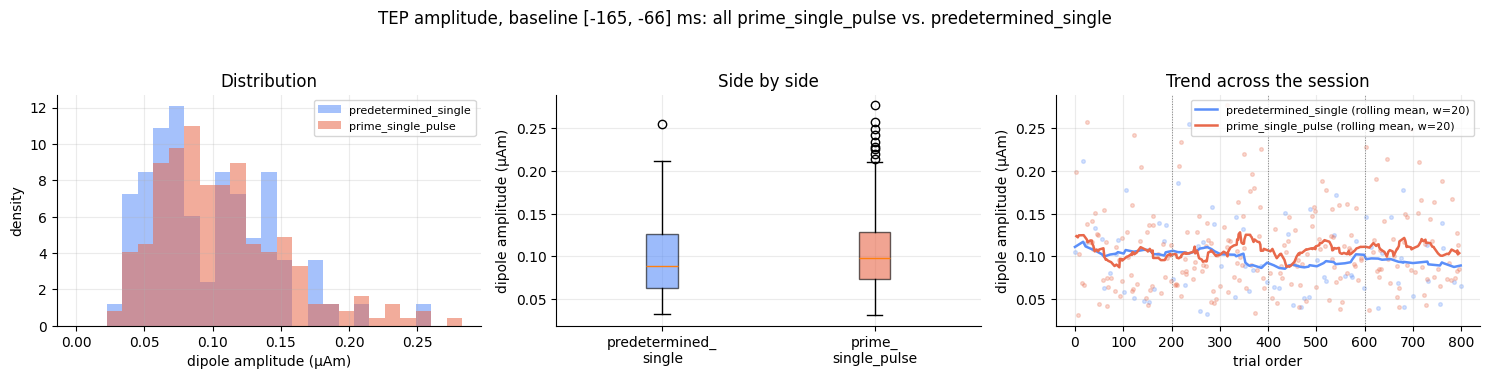

prime_single_pulse   median = 0.0977 µAm  (n=217)
predetermined_single median = 0.0888 µAm  (n=73)
difference in medians (prime - predetermined) = +0.0089 µAm


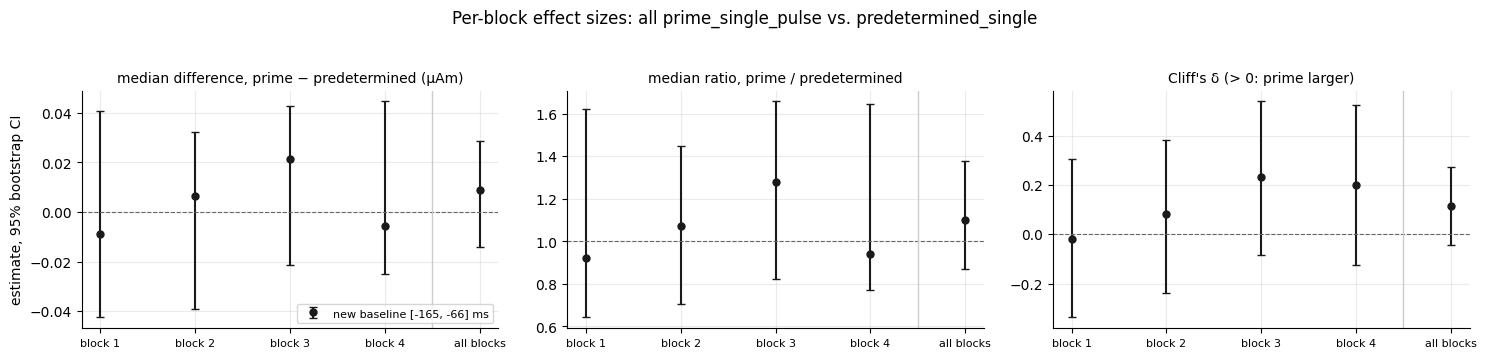

n prime  n predetermined  \
baseline                    block                                  
new baseline [-165, -66] ms block 1          54               18   
                            block 2          58               19   
                            block 3          54               19   
                            block 4          51               17   
                            all blocks      217               73   

                                        median diff (µAm) [95% CI]  \
baseline                    block                                    
new baseline [-165, -66] ms block 1     -0.0088 [-0.0425, +0.0407]   
                            block 2     +0.0066 [-0.0391, +0.0323]   
                            block 3     +0.0213 [-0.0212, +0.0427]   
                            block 4     -0.0056 [-0.0251, +0.0446]   
                            all blocks  +0.0089 [-0.0143, +0.0285]   

                                           ratio [95% CI]  \
baseline                    block                           
new baseline [-165, -66] ms block 1     0.92 [0.64, 1.62]   
                            block 2     1.07 [0.71, 1.45]   
                            block 3     1.28 [0.82, 1.66]   
                            block 4     0.94 [0.77, 1.65]   
                            all blocks  1.10 [0.87, 1.38]   

                                          Cliff's δ [95% CI] p (MWU)  
baseline                    block                                     
new baseline [-165, -66] ms block 1     -0.02 [-0.34, +0.30]   0.902  
                            block 2     +0.08 [-0.24, +0.38]   0.599  
                            block 3     +0.23 [-0.09, +0.54]   0.133  
                            block 4     +0.20 [-0.12, +0.52]   0.218  
                            all blocks  +0.12 [-0.04, +0.28]   0.139

In [169]:
amplitude_comparison(kept, "all prime_single_pulse")

### 7b · Forced `prime_single_pulse` trials excluded

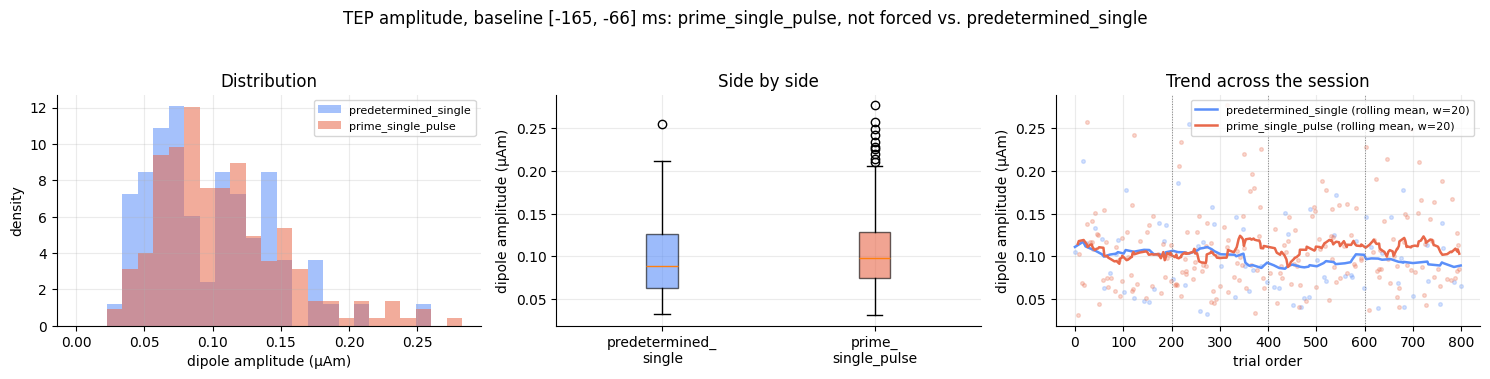

prime_single_pulse   median = 0.0980 µAm  (n=198)
predetermined_single median = 0.0888 µAm  (n=73)
difference in medians (prime - predetermined) = +0.0092 µAm


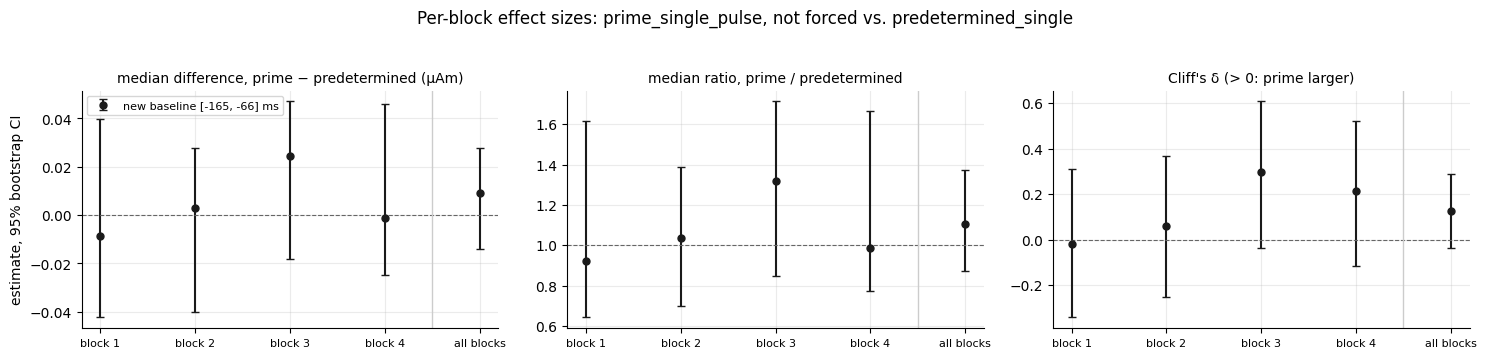

n prime  n predetermined  \
baseline                    block                                  
new baseline [-165, -66] ms block 1          48               18   
                            block 2          55               19   
                            block 3          46               19   
                            block 4          49               17   
                            all blocks      198               73   

                                        median diff (µAm) [95% CI]  \
baseline                    block                                    
new baseline [-165, -66] ms block 1     -0.0088 [-0.0423, +0.0397]   
                            block 2     +0.0030 [-0.0399, +0.0277]   
                            block 3     +0.0244 [-0.0180, +0.0471]   
                            block 4     -0.0011 [-0.0249, +0.0461]   
                            all blocks  +0.0092 [-0.0138, +0.0279]   

                                           ratio [95% CI]  \
baseline                    block                           
new baseline [-165, -66] ms block 1     0.92 [0.64, 1.62]   
                            block 2     1.03 [0.70, 1.39]   
                            block 3     1.32 [0.85, 1.71]   
                            block 4     0.99 [0.77, 1.67]   
                            all blocks  1.10 [0.87, 1.38]   

                                          Cliff's δ [95% CI] p (MWU)  
baseline                    block                                     
new baseline [-165, -66] ms block 1     -0.02 [-0.34, +0.31]   0.914  
                            block 2     +0.06 [-0.25, +0.37]    0.71  
                            block 3     +0.30 [-0.04, +0.61]  0.0618  
                            block 4     +0.21 [-0.11, +0.52]   0.197  
                            all blocks  +0.13 [-0.04, +0.29]   0.108

In [170]:
amplitude_comparison(kept[~kept.is_forced], "prime_single_pulse, not forced")

## 8 · Online vs. new baseline, side by side

These are the box plot and the session trend from section 7, without the distribution panel, drawn
for both baselines:

- the top row uses the online baseline (`amp_online`);
- the bottom row uses `BASELINE` (`amp_new`).

Both rows show the same trials (`kept`), so the baseline window is the only difference. All four
panels share one y-axis. The table below each figure gives the medians for both baselines. The
last column states the prime − predetermined gap as a percentage of the predetermined median, so
the gap can be compared between baselines even when their overall amplitude differs.

Below that come the per-block effect sizes from section 7 for both baselines, in grey (online)
and black (new), on the same trials.

In [171]:
def amplitude_comparison_both(d, name):
    # Section 7 without the distribution panel, once per baseline (rows); same trials in both rows.
    conds = [("predetermined_single", COLOR_PREDETERMINED), ("prime_single_pulse", COLOR_PRIME_SINGLE)]
    rows = [("amp_online", f"online baseline {ms(ONLINE_BASELINE)}"),
            ("amp_new", f"new baseline {ms(BASELINE)}")]
    fig, axes = plt.subplots(2, 2, figsize=(15, 7.5), sharey=True, gridspec_kw={"width_ratios": [1, 2.4]})

    medians = {}
    for (col, label), (ax_box, ax_trend) in zip(rows, axes):
        bp = ax_box.boxplot([d.loc[d.condition == c, col].dropna() for c, _ in conds],
                            tick_labels=["predetermined_\nsingle", "prime_\nsingle_pulse"], patch_artist=True)
        for patch, (_, color) in zip(bp["boxes"], conds):
            patch.set_facecolor(color)
            patch.set_alpha(0.6)
        ax_box.set_ylabel(f"{label}\ndipole amplitude (µAm)")

        trend_plot(ax_trend, d, col, [c for c, _ in conds], [c for _, c in conds])
        ax_trend.set_ylabel("")

        a = d.loc[d.condition == "prime_single_pulse", col].dropna()
        b = d.loc[d.condition == "predetermined_single", col].dropna()
        medians[label] = {"n prime": len(a), "n predetermined": len(b),
                          "median prime (µAm)": a.median(), "median predetermined (µAm)": b.median(),
                          "prime - predetermined (µAm)": a.median() - b.median(),
                          "prime - predetermined (%)": 100 * (a.median() - b.median()) / b.median()}

    axes[0, 0].set_title("Side by side")
    axes[0, 1].set_title("Trend across the session")
    fig.suptitle(f"TEP amplitude, online vs. new baseline: {name} vs. predetermined_single", y=1.01)
    fig.tight_layout()
    plt.show()
    display(pd.DataFrame.from_dict(medians, orient="index").rename_axis("baseline").round(4))
    block_effect_report(d, name, ["amp_online", "amp_new"])

### 8a · All `prime_single_pulse` trials (forced included)

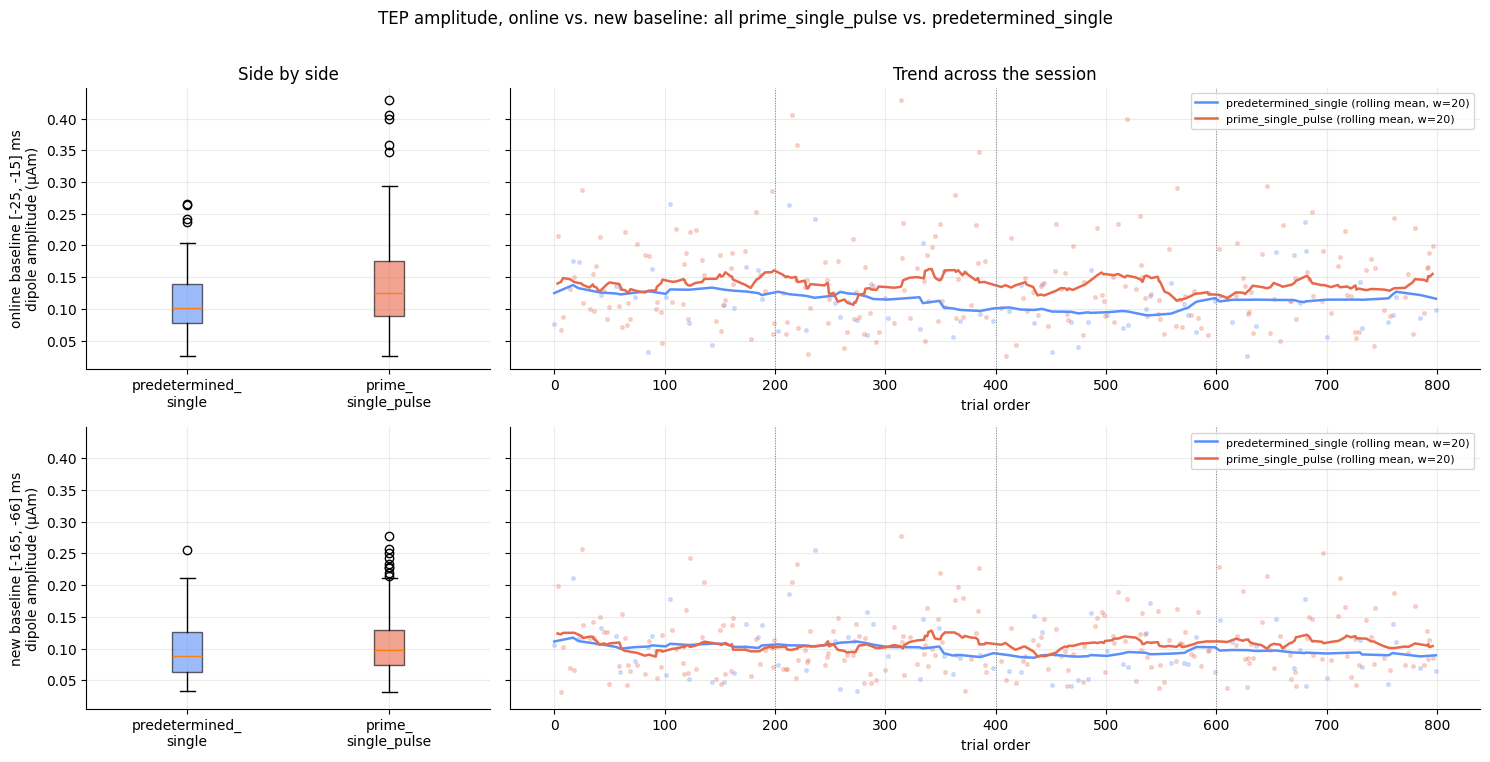

,n prime,n predetermined,median prime (µAm),median predetermined (µAm),prime - predetermined (µAm),prime - predetermined (%)
baseline,,,,,,
"online baseline [-25, -15] ms",217,73,0.1247,0.1019,0.0228,22.3553
"new baseline [-165, -66] ms",217,73,0.0977,0.0888,0.0089,10.0054


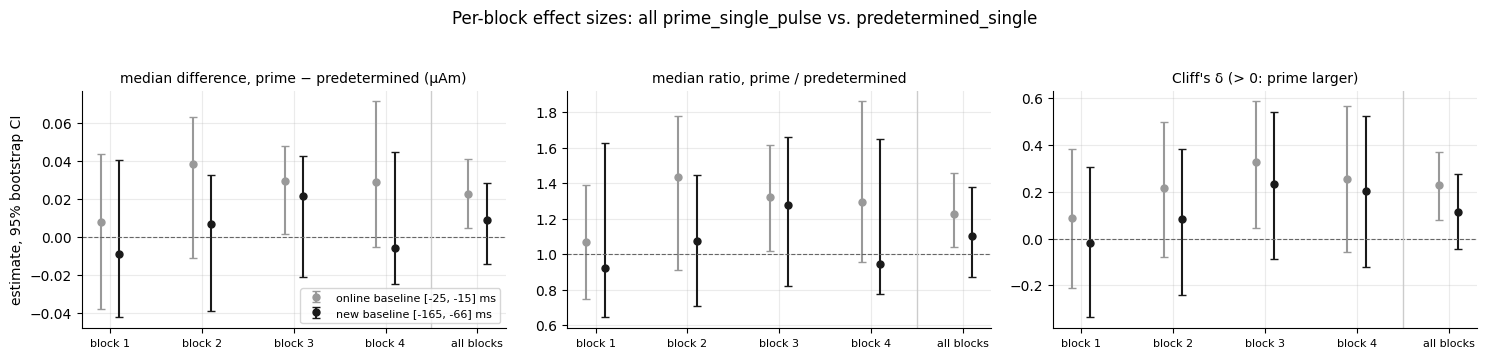

n prime  n predetermined  \
baseline                      block                                  
online baseline [-25, -15] ms block 1          54               18   
                              block 2          58               19   
                              block 3          54               19   
                              block 4          51               17   
                              all blocks      217               73   
new baseline [-165, -66] ms   block 1          54               18   
                              block 2          58               19   
                              block 3          54               19   
                              block 4          51               17   
                              all blocks      217               73   

                                          median diff (µAm) [95% CI]  \
baseline                      block                                    
online baseline [-25, -15] ms block 1     +0.0080 [-0.0381, +0.0439]   
                              block 2     +0.0382 [-0.0110, +0.0634]   
                              block 3     +0.0292 [+0.0016, +0.0481]   
                              block 4     +0.0289 [-0.0054, +0.0714]   
                              all blocks  +0.0228 [+0.0044, +0.0408]   
new baseline [-165, -66] ms   block 1     -0.0088 [-0.0425, +0.0407]   
                              block 2     +0.0066 [-0.0391, +0.0323]   
                              block 3     +0.0213 [-0.0212, +0.0427]   
                              block 4     -0.0056 [-0.0251, +0.0446]   
                              all blocks  +0.0089 [-0.0143, +0.0285]   

                                             ratio [95% CI]  \
baseline                      block                           
online baseline [-25, -15] ms block 1     1.07 [0.75, 1.39]   
                              block 2     1.44 [0.91, 1.78]   
                              block 3     1.32 [1.01, 1.62]   
                              block 4     1.29 [0.95, 1.86]   
                              all blocks  1.22 [1.04, 1.46]   
new baseline [-165, -66] ms   block 1     0.92 [0.64, 1.62]   
                              block 2     1.07 [0.71, 1.45]   
                              block 3     1.28 [0.82, 1.66]   
                              block 4     0.94 [0.77, 1.65]   
                              all blocks  1.10 [0.87, 1.38]   

                                            Cliff's δ [95% CI]  p (MWU)  
baseline                      block                                      
online baseline [-25, -15] ms block 1     +0.09 [-0.21, +0.38]     0.58  
                              block 2     +0.22 [-0.08, +0.50]    0.161  
                              block 3     +0.33 [+0.05, +0.59]   0.0363  
                              block 4     +0.25 [-0.06, +0.57]    0.119  
                              all blocks  +0.23 [+0.08, +0.37]  0.00339  
new baseline [-165, -66] ms   block 1     -0.02 [-0.34, +0.30]    0.902  
                              block 2     +0.08 [-0.24, +0.38]    0.599  
                              block 3     +0.23 [-0.09, +0.54]    0.133  
                              block 4     +0.20 [-0.12, +0.52]    0.218  
                              all blocks  +0.12 [-0.04, +0.28]    0.139

In [172]:
amplitude_comparison_both(kept, "all prime_single_pulse")

### 8b · Forced `prime_single_pulse` trials excluded

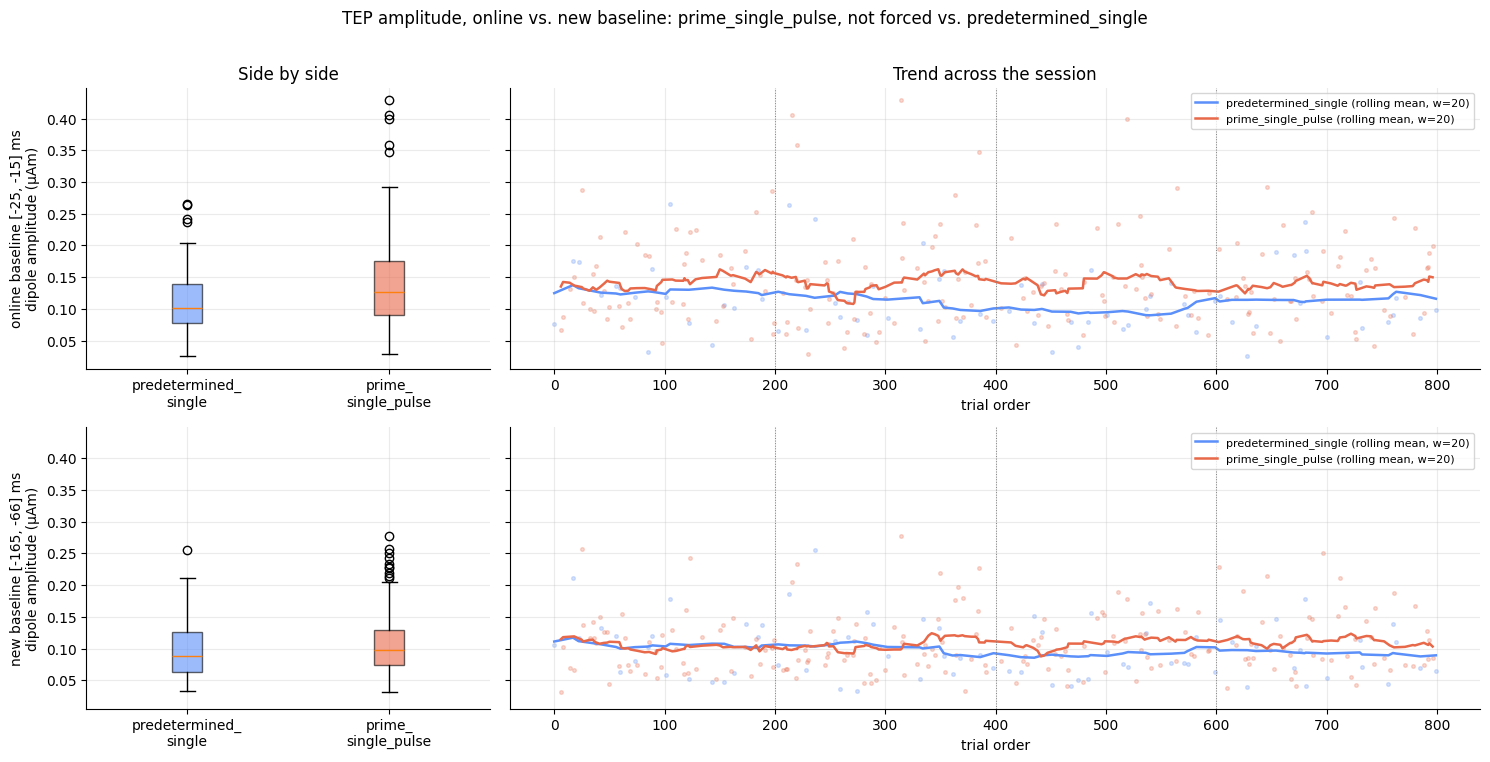

,n prime,n predetermined,median prime (µAm),median predetermined (µAm),prime - predetermined (µAm),prime - predetermined (%)
baseline,,,,,,
"online baseline [-25, -15] ms",198,73,0.1264,0.1019,0.0245,24.0370
"new baseline [-165, -66] ms",198,73,0.0980,0.0888,0.0092,10.3414


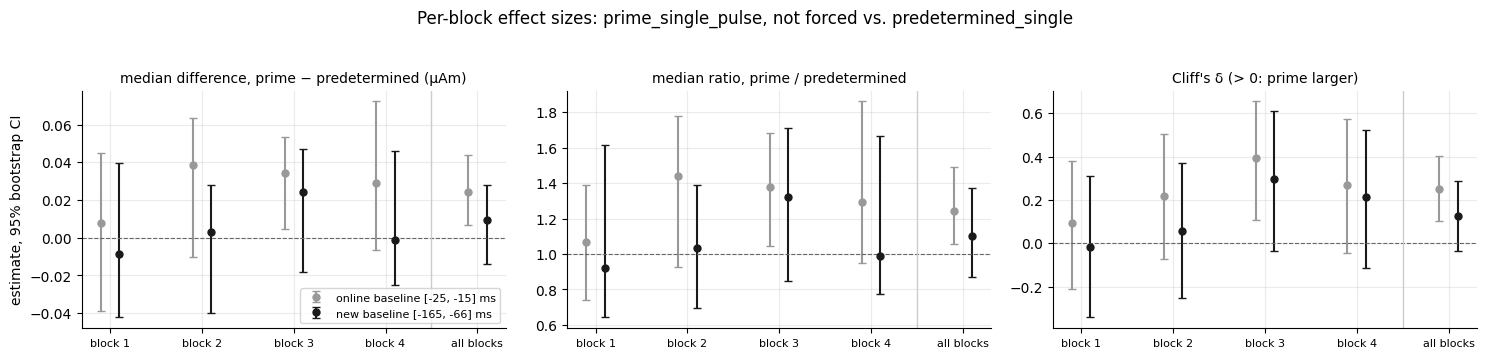

n prime  n predetermined  \
baseline                      block                                  
online baseline [-25, -15] ms block 1          48               18   
                              block 2          55               19   
                              block 3          46               19   
                              block 4          49               17   
                              all blocks      198               73   
new baseline [-165, -66] ms   block 1          48               18   
                              block 2          55               19   
                              block 3          46               19   
                              block 4          49               17   
                              all blocks      198               73   

                                          median diff (µAm) [95% CI]  \
baseline                      block                                    
online baseline [-25, -15] ms block 1     +0.0080 [-0.0387, +0.0449]   
                              block 2     +0.0388 [-0.0102, +0.0637]   
                              block 3     +0.0341 [+0.0047, +0.0536]   
                              block 4     +0.0289 [-0.0062, +0.0724]   
                              all blocks  +0.0245 [+0.0065, +0.0439]   
new baseline [-165, -66] ms   block 1     -0.0088 [-0.0423, +0.0397]   
                              block 2     +0.0030 [-0.0399, +0.0277]   
                              block 3     +0.0244 [-0.0180, +0.0471]   
                              block 4     -0.0011 [-0.0249, +0.0461]   
                              all blocks  +0.0092 [-0.0138, +0.0279]   

                                             ratio [95% CI]  \
baseline                      block                           
online baseline [-25, -15] ms block 1     1.07 [0.74, 1.39]   
                              block 2     1.44 [0.92, 1.78]   
                              block 3     1.38 [1.04, 1.68]   
                              block 4     1.29 [0.95, 1.86]   
                              all blocks  1.24 [1.06, 1.49]   
new baseline [-165, -66] ms   block 1     0.92 [0.64, 1.62]   
                              block 2     1.03 [0.70, 1.39]   
                              block 3     1.32 [0.85, 1.71]   
                              block 4     0.99 [0.77, 1.67]   
                              all blocks  1.10 [0.87, 1.38]   

                                            Cliff's δ [95% CI]  p (MWU)  
baseline                      block                                      
online baseline [-25, -15] ms block 1     +0.09 [-0.21, +0.38]     0.56  
                              block 2     +0.22 [-0.07, +0.50]    0.162  
                              block 3     +0.39 [+0.11, +0.65]   0.0134  
                              block 4     +0.27 [-0.04, +0.57]    0.101  
                              all blocks  +0.25 [+0.10, +0.40]  0.00144  
new baseline [-165, -66] ms   block 1     -0.02 [-0.34, +0.31]    0.914  
                              block 2     +0.06 [-0.25, +0.37]     0.71  
                              block 3     +0.30 [-0.04, +0.61]   0.0618  
                              block 4     +0.21 [-0.11, +0.52]    0.197  
                              all blocks  +0.13 [-0.04, +0.29]    0.108

In [173]:
amplitude_comparison_both(kept[~kept.is_forced], "prime_single_pulse, not forced")

## Summary

The correlations from section 6 and the medians from section 7, each with the online baseline
next to the new baseline.

In [174]:
print(f"trial set: REJECTION = {REJECTION!r}, {len(kept)} single-pulse trials\n")
corr_table = pd.DataFrame(
    [{"trials": name, "n": CORR[(name, "amp_online")][0],
      "r online": CORR[(name, "amp_online")][1], "p online": CORR[(name, "amp_online")][2],
      "r new": CORR[(name, "amp_new")][1], "p new": CORR[(name, "amp_new")][2],
      "ρ online": CORR[(name, "amp_online")][3], "ρ new": CORR[(name, "amp_new")][3]}
     for name in dict.fromkeys(k[0] for k in CORR)]).set_index("trials")
print("prediction_probability vs. dipole amplitude")
display(corr_table.round(3))

median_table = pd.DataFrame(
    [{"prime trials": name, "baseline": "online" if c == "amp_online" else "new",
      "n prime": v[2], "n predetermined": v[3],
      "median prime (µAm)": v[0], "median predetermined (µAm)": v[1], "prime - predetermined (µAm)": v[0] - v[1]}
     for (name, c), v in MEDIANS.items()]).set_index(["prime trials", "baseline"])
print("TEP amplitude medians, prime_single_pulse vs. predetermined_single")
display(median_table.round(4))

trial set: REJECTION = 'online', 290 single-pulse trials

prediction_probability vs. dipole amplitude


,n,r online,p online,r new,p new,ρ online,ρ new
trials,,,,,,,
all single pulses,268,0.173,0.005,0.093,0.130,0.191,0.119
predetermined_single,70,0.042,0.728,0.003,0.980,0.056,-0.040
prime_single_pulse (not forced),198,0.052,0.467,0.056,0.435,0.071,0.075


TEP amplitude medians, prime_single_pulse vs. predetermined_single


n prime  n predetermined  \
prime trials                   baseline                             
all prime_single_pulse         online        217               73   
                               new           217               73   
prime_single_pulse, not forced online        198               73   
                               new           198               73   

                                         median prime (µAm)  \
prime trials                   baseline                       
all prime_single_pulse         online                0.1247   
                               new                   0.0977   
prime_single_pulse, not forced online                0.1264   
                               new                   0.0980   

                                         median predetermined (µAm)  \
prime trials                   baseline                               
all prime_single_pulse         online                        0.1019   
                               new                           0.0888   
prime_single_pulse, not forced online                        0.1019   
                               new                           0.0888   

                                         prime - predetermined (µAm)  
prime trials                   baseline                               
all prime_single_pulse         online                         0.0228  
                               new                            0.0089  
prime_single_pulse, not forced online                         0.0245  
                               new                            0.0092